# Replay the final bank marketing results
Run **Runtime → Run all**. This notebook only displays approved archived aggregates and images. It never loads a model, dataset records or row-level predictions, and never repeats training, inference, held-out evaluation, bootstrap or explanations.

P1 remains the sole primary historical academic scenario. All predictors are Provisional. Top 10% is an illustrative capacity, not a bank requirement.

## Setup — get the whole repository
A public repository is cloned automatically into `/content/bank-marketing-ml` in Colab (or the current directory locally). An existing checkout is used without updates or overwrites. For private access, use an authorized GitHub connection or upload one approved repository ZIP, extract it using Colab's Files panel, and set `PROJECT_DIR_OVERRIDE` to the extracted root. Never paste credentials into this notebook. ZIP contents must include `results/` and `figures/`; individual uploads are unnecessary.

In [1]:
from pathlib import Path
import subprocess, sys, importlib.util
PROJECT_DIR_OVERRIDE = ""  # Optional: e.g. /content/bank-marketing-ml-main
base = Path('/content') if Path('/content').is_dir() else Path.cwd()
PROJECT_DIR = Path(PROJECT_DIR_OVERRIDE).expanduser().resolve() if PROJECT_DIR_OVERRIDE else base / 'bank-marketing-ml'
if not PROJECT_DIR_OVERRIDE and not PROJECT_DIR.exists():
    subprocess.run(['git', 'clone', '--branch', 'main', '--single-branch',
                    'https://github.com/amyfish1999/bank-marketing-ml.git', str(PROJECT_DIR)], check=True)
if not PROJECT_DIR.is_dir():
    raise FileNotFoundError('Repository root missing. Extract an approved ZIP and set PROJECT_DIR_OVERRIDE.')
# Colab normally includes these. Install only missing display dependencies.
missing = [package for package in ['pandas', 'matplotlib', 'IPython'] if importlib.util.find_spec(package) is None]
if missing:
    subprocess.run([sys.executable, '-m', 'pip', 'install', *missing], check=True)
print('Archive root:', PROJECT_DIR)


Archive root: /tmp/colab-replay-3kbekdp6/content/bank-marketing-ml


## Validate the archive before displaying results
The expected SHA-256 values below pin the approved artifacts verified against merged `main` (`d41bd3450b17370c8f364c895f3771e5b0a093f4`). Only the listed aggregate/doc/image files are read. Model files and row-level files are not opened, even for hashing. A digest disagreement is a **FAIL**, not permission to substitute values. The manifests provide additional cross-checks; bootstrap interval estimates must agree with the archived point estimates.

In [2]:
import json, hashlib, math, io
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
EXPECTED_SHA256 = {'11_final_training_and_test_summary.md': '9eaee1215ef0584eadf166a80c9642f9cf05eadcd1d48da67fad5f949434d3ee', '12_pre_holdout_release_gate.md': 'b12f5252aef6794c635a041506a01ae388b141e9f91973afb612d155bb07ba89', '16_executive_summary.md': '308f3f9dec716db62c03603f24ad99bfbfa5a2cef1f98008679c5dfd77673a1e', '06_nested_cv_targeting_summary.md': 'd9e58462856baf3362e18e7bc4fcaf56d0ddb5db5656f5d7b867b2f6dca642c2', '07_threshold_decision_summary.md': '2756204930ef61d624fe80078e51a469db937f10e0678963d708fda52c3b2c2a', '08_imbalance_treatment_summary.md': 'ecdf9a78178a59ecb8ddbc058b5a02d1be3c590f15111c071124d97bde8a1d51', '09_feature_ablation_summary.md': 'b396bd3df7226d9bbe233968e1eecf0f89825065d133366796dca2d5b101fe1f', 'models/model_manifest.json': '84aad6db0ad97b619fdf27c4e6fccdef3263ac65c178ca4f9898a0b0b773d96a', 'results/evaluation_complete.json': '1942e89be766286b6b108acb2383b5326e318e9023d509ec573045a1cd60284f', 'results/release_gate.json': 'd9a5faa9cd7cd47fd925f92c1ead26a2f2c1289e497ffd154c3fc6be3a64bc1d', 'results/heldout_metrics.csv': 'e75b81da314a3b182a7fa7f6da02e31483c123dcf5e1defaab53a7cc2eed5655', 'results/heldout_topk.csv': 'a319e3041e42afe5e4440624aa8af26596a74e2408c54bfc8bc18e2d64df1068', 'results/bootstrap_intervals.csv': 'a180a06e3633dc1eb6e5f1aeec19321d2381f18220b2a5095ebaf15f14800ee5', 'results/final_selected_parameters.csv': '753116478343c5054b3669979d52ece7d13013597b5a10b7328e2b30dbe05048', 'figures/data/figure_inventory.json': '381c4af28862aa4189ac64919a0df42503495c009d23e8931e984bd6913a7ae1', 'figures/data/phase8_validation.json': '0a8be2da7191ac977af7c6f5280b57e7c803df992eb92abbd3e62a179bec41d0', 'figures/01_research_workflow.png': '235d1ebb6529a651f0fde894585571791c43d15083cb66bad927affe44659676', 'figures/02_class_distribution.png': '0059aeeb4216f7f40b5d11645fc9e47f47d32ee8576050f78bc00a182e7b5de0', 'figures/03_model_comparison.png': '13a6d300772335a7be587ddb0e21f2f45a5ca1ca3415c487cb00976067a8abdc', 'figures/04_threshold_tradeoff.png': '430b42b98c9aa7bc81eea1c9eabbc8131a74241a577bd538eeb077c6d469276f', 'figures/05_imbalance_ap.png': '884139a4a2fe4686522373bd7aa5e56e7e0333e551b1a13d07a5724ddb786f7d', 'figures/06_feature_ablation.png': '0b77c578e9fd0eab9e9d2f04faa91c7f766112a0422f9050fcf54e05fe29c6fe', 'figures/07_heldout_performance.png': '535b7b36459e16855888a4e8d42116f735882473f43fc34c621f54f357950ea7', 'figures/08_topk_targeting.png': '199437b1b9f0fc5018803f032839e017e1d45537c383766d5bf8858601b1b4ed', 'figures/09_permutation_individual.png': '6a489120cd940540fcb3969488f8c4f00167d325a58f430306425847732ddf7a', 'figures/10_permutation_groups.png': '0f26c400b92d76c4431916bae336f3dec82c3281b85ca1fe04c32226ed284a99', 'figures/11_shap_beeswarm.png': '84943d9a1682d5f07cf491156a4a89256763b24239d4c6539f50b411c2c9e97c', 'figures/12_shap_grouped_bar.png': 'b7f1cdd7108558799fcc04eb32b8555a1c144920b10849ea723690ea193b6b46', 'figures/13_shap_dependence.png': 'cdac4cd930cdd3c5269b547cb8eb582aad03aa3ef8301d092ce2d9c5341f37ad', 'figures/14_shap_local_high.png': '8a73798ee6a75f2dcb2b877a8b87c59ec91f8dc0818c40ee7d29a17f39a08118', 'figures/15_shap_local_medium.png': 'ee716b9f615d209c19b87e22010384a7276de80dc6d540350077eed3cdcfed17', 'figures/16_shap_local_low.png': 'b3532e115ee01f551fc21ae688f2bb2e2cb2bd114283446c19fb18fec1e4981c', 'figures/17_lr_coefficients.png': '8995d7b7bade2fd8e7e5128ca4d0bc9c1c3754ad94870fa7818dcd76db713953'}
ARCHIVE = {}
try:
    for relative, expected in EXPECTED_SHA256.items():
        path = PROJECT_DIR / relative
        if not path.is_file():
            raise FileNotFoundError(f'Missing required archive: {relative}. Restore from the approved repository; do not recalculate.')
        data = path.read_bytes()
        if hashlib.sha256(data).hexdigest() != expected:
            raise ValueError(f'Archive digest disagreement: {relative}. Stop and ask the team to review the source version.')
        ARCHIVE[relative] = data
    def read_json(relative):
        return json.loads(ARCHIVE[relative])
    def read_csv(relative):
        return pd.read_csv(io.BytesIO(ARCHIVE[relative]), float_precision='round_trip')
    completed = read_json('results/evaluation_complete.json')
    manifest = read_json('models/model_manifest.json')
    assert completed['scenario_order'] == ['P1', 'S1', 'B1', 'B2']
    assert completed['primary_scenario'] == 'P1'
    assert read_json('results/release_gate.json')['status'] == 'PASS'
    assert read_json('figures/data/phase8_validation.json')['status'] == 'PASS'
    assert hashlib.sha256(ARCHIVE['models/model_manifest.json']).hexdigest() == completed['manifest_sha256']
    for relative in ['results/heldout_metrics.csv','results/heldout_topk.csv','results/bootstrap_intervals.csv','results/final_selected_parameters.csv','results/release_gate.json']:
        assert EXPECTED_SHA256[relative] == completed['result_hashes'][relative], relative
    phase8 = read_json('figures/data/phase8_validation.json')['files_sha256']
    inventory = read_json('figures/data/figure_inventory.json')
    assert len(inventory) == 17
    for item in inventory:
        relative = 'figures/' + item['filename']
        assert EXPECTED_SHA256[relative] == phase8[relative], relative
    metrics = read_csv('results/heldout_metrics.csv').set_index('scenario').loc[completed['scenario_order']]
    topk = read_csv('results/heldout_topk.csv')
    intervals = read_csv('results/bootstrap_intervals.csv').set_index(['scenario','metric'])
    selected = read_csv('results/final_selected_parameters.csv')
    assert len(metrics) == 4 and len(topk) == 12
    for scenario, row in metrics.iterrows():
        for metric in metrics.select_dtypes('number').columns:
            ci = intervals.loc[(scenario, metric)]
            assert math.isclose(row[metric], ci['estimate'], rel_tol=0, abs_tol=1e-12), (scenario,metric)
    for _, row in topk.iterrows():
        for metric in ['contacts','captured_subscribers','Precision_at_K','Recall_at_K','Lift_at_K']:
            key = f"Top{round(row['fraction']*100)}_{metric}"
            assert math.isclose(row[metric], intervals.loc[(row['scenario'],key),'estimate'], rel_tol=0,abs_tol=1e-12), key
    assert set(selected.scenario) == set(metrics.index)
    REPLAY_OK = True
    display(Markdown('**PASS — required archive digests, scenario roster, release status and aggregate point-estimate/interval consistency verified.**'))
except Exception as exc:
    REPLAY_OK = False
    display(Markdown(f'**FAIL — replay stopped:** {exc}'))
    raise

def source(*paths):
    links = [f'[{p}](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/{p})' for p in paths]
    display(Markdown('Source: ' + '; '.join(links)))

def archived_figure(filename):
    assert REPLAY_OK
    item = next(x for x in inventory if x['filename'] == filename)
    display(Image(data=ARCHIVE['figures/'+filename]))
    display(Markdown(f"**{filename}:** {item['caption']}  \nContext/source: {item['source']}"))
    source('figures/'+filename, 'figures/figure_inventory.md')


**PASS — required archive digests, scenario roster, release status and aggregate point-estimate/interval consistency verified.**

## A — Project overview
The question is which customers are more likely to subscribe to a term deposit. The approved cleaned cohort has **41,176** observations: **32,940** Development and **8,236** Held-out Test. These are recorded study sizes, not newly counted rows. Models were frozen before a one-time test batch.

**P1:** Full HGB, sole primary. **S1:** Customer-only HGB, sensitivity. **B1:** Full LR, benchmark. **B2:** Customer-only LR, benchmark. Full means 15 predictors; customer-only means seven. No scenario is certified deployment-ready.

,scenario,role,group,selected_parameters,CV_AP_selection_only
0,P1,Sole Primary,Full,"{""classifier__l2_regularization"": 1.0, ""classi...",0.448069
1,S1,Secondary Sensitivity,Customer Attributes Only,"{""classifier__l2_regularization"": 0.0, ""classi...",0.233785
2,B1,Secondary Benchmark,Full,"{""classifier__C"": 0.1}",0.422429
3,B2,Secondary Benchmark,Customer Attributes Only,"{""classifier__C"": 0.1}",0.202251


Source: [results/final_selected_parameters.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/final_selected_parameters.csv); [11_final_training_and_test_summary.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/11_final_training_and_test_summary.md)

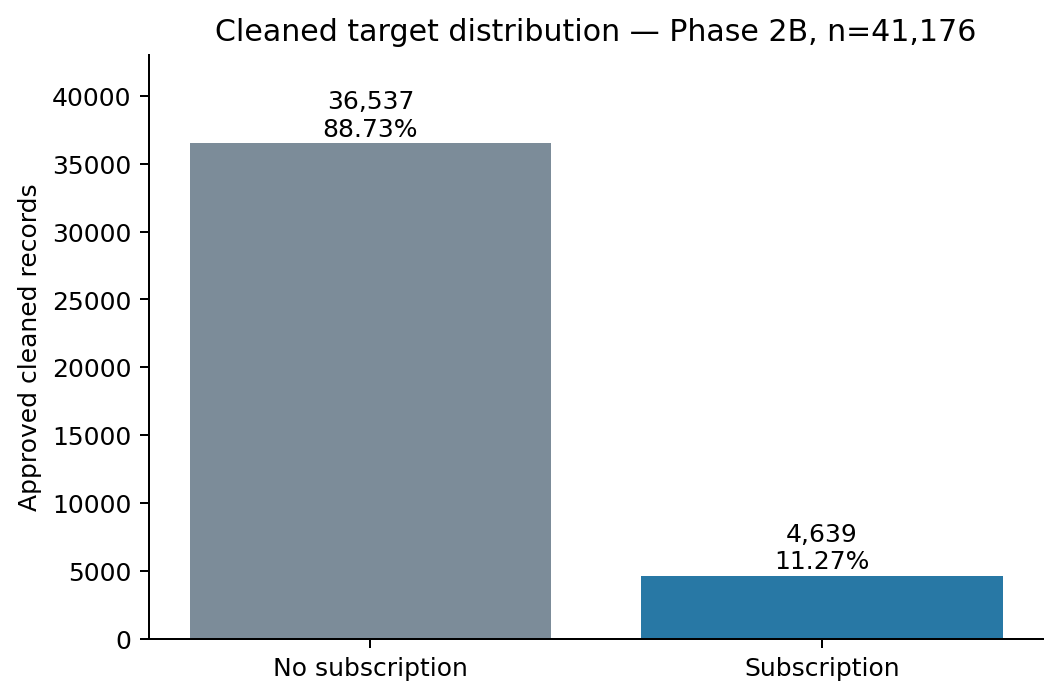

**02_class_distribution.png:** Approved cleaned class counts from Phase 2B; no new inspection of held-out rows.  
Context/source: 02_data_cleaning_summary.md; archived counts

Source: [figures/02_class_distribution.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/02_class_distribution.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

In [3]:
assert REPLAY_OK
display(selected[['scenario','role','group','selected_parameters','CV_AP_selection_only']])
source('results/final_selected_parameters.csv','11_final_training_and_test_summary.md')
archived_figure('02_class_distribution.png')

## B — Final model comparison (archived Held-out Test)
AP summarizes precision across recall levels and is useful for an imbalanced target. ROC-AUC describes ranking discrimination. The recorded 95% intervals are descriptive, conditional on frozen fitted models and observed class counts. They do not include model-selection uncertainty or establish future-campaign performance. The selection-only CV score above is not an independent test estimate.

,role,AP,ROC_AUC,AP 95% interval,ROC_AUC 95% interval
scenario,,,,,
P1,Sole Primary,0.4513,0.8076,"[0.4206, 0.4853]","[0.7906, 0.8245]"
S1,Secondary Sensitivity,0.2310,0.6698,"[0.2111, 0.2547]","[0.6510, 0.6876]"
B1,Secondary Benchmark,0.4310,0.7773,"[0.4008, 0.4634]","[0.7591, 0.7962]"
B2,Secondary Benchmark,0.2004,0.6485,"[0.1838, 0.2214]","[0.6303, 0.6655]"


Source: [results/heldout_metrics.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/heldout_metrics.csv); [results/bootstrap_intervals.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/bootstrap_intervals.csv)

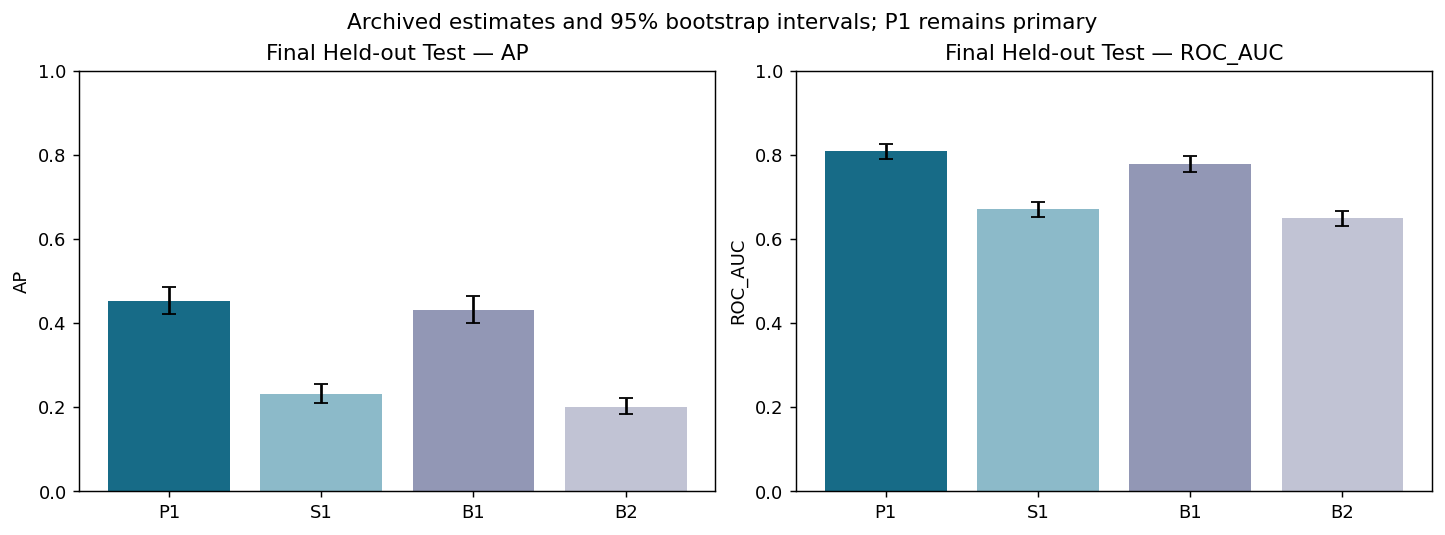

Source: [results/heldout_metrics.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/heldout_metrics.csv); [results/bootstrap_intervals.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/bootstrap_intervals.csv)

In [4]:
assert REPLAY_OK
comparison = metrics[['role','AP','ROC_AUC']].copy()
for metric in ['AP','ROC_AUC']:
    comparison[metric+' 95% interval'] = [f"[{intervals.loc[(s,metric),'lower_95']:.4f}, {intervals.loc[(s,metric),'upper_95']:.4f}]" for s in comparison.index]
display(comparison.round({'AP':4,'ROC_AUC':4}))
source('results/heldout_metrics.csv','results/bootstrap_intervals.csv')
fig, axes = plt.subplots(1,2,figsize=(11,4),layout='constrained')
for ax, metric in zip(axes,['AP','ROC_AUC']):
    values = metrics[metric]
    lows = [intervals.loc[(s,metric),'lower_95'] for s in metrics.index]
    highs = [intervals.loc[(s,metric),'upper_95'] for s in metrics.index]
    ax.bar(metrics.index,values,color=['#176b87','#8cbac9','#9297b5','#c1c3d4'])
    ax.errorbar(range(4),values,yerr=[values.to_numpy()-lows, highs-values.to_numpy()],fmt='none',color='black',capsize=4)
    ax.set(title=f'Final Held-out Test — {metric}',ylabel=metric,ylim=(0,1))
fig.suptitle('Archived estimates and 95% bootstrap intervals; P1 remains primary')
plt.show()
source('results/heldout_metrics.csv','results/bootstrap_intervals.csv')


## C — Fixed-capacity business targeting (archived Held-out Test)
Top 5%, 10% and 20% mean contacting 412, 824 and 1,648 ranked records. Top 10% is the primary **illustrative** capacity. Precision@K is the selected group's historical subscription rate, Recall@K is the fraction of historical subscribers captured, and Lift@K compares that rate with cohort prevalence. These are historical associations, not subscriptions caused by a call.

,scenario,fraction,capacity_role,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,P1,0.05,Secondary,412,248,0.6019,0.2672,5.3422
1,P1,0.10,Primary illustrative,824,412,0.5000,0.4440,4.4375
2,P1,0.20,Secondary,1648,610,0.3701,0.6573,3.2850
3,S1,0.05,Secondary,412,156,0.3786,0.1681,3.3604
4,S1,0.10,Primary illustrative,824,224,0.2718,0.2414,2.4126
5,S1,0.20,Secondary,1648,338,0.2051,0.3642,1.8202
6,B1,0.05,Secondary,412,240,0.5825,0.2586,5.1699
7,B1,0.10,Primary illustrative,824,396,0.4806,0.4267,4.2652
8,B1,0.20,Secondary,1648,586,0.3556,0.6315,3.1558
9,B2,0.05,Secondary,412,123,0.2985,0.1325,2.6496


Source: [results/heldout_topk.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/heldout_topk.csv)

**P1 sole primary — all predefined capacities:**

,scenario,fraction,capacity_role,contacts,captured_subscribers,Precision_at_K,Recall_at_K,Lift_at_K
0,P1,0.05,Secondary,412,248,0.601942,0.267241,5.342233
1,P1,0.10,Primary illustrative,824,412,0.500000,0.443966,4.437500
2,P1,0.20,Secondary,1648,610,0.370146,0.657328,3.285042


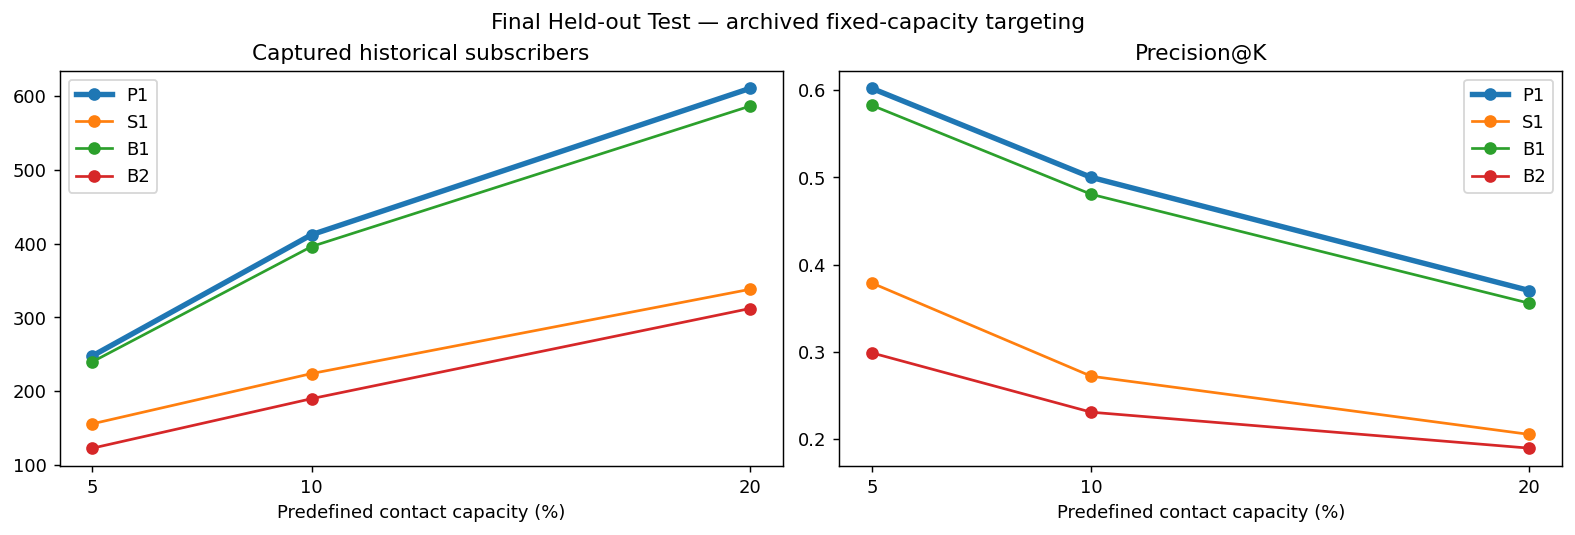

Source: [results/heldout_topk.csv](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/results/heldout_topk.csv)

In [5]:
assert REPLAY_OK
display(topk.round({'fraction':2,'Precision_at_K':4,'Recall_at_K':4,'Lift_at_K':4}))
source('results/heldout_topk.csv')
display(Markdown('**P1 sole primary — all predefined capacities:**'))
display(topk[topk.scenario=='P1'])
fig, axes = plt.subplots(1,2,figsize=(12,4),layout='constrained')
for scenario in metrics.index:
    rows = topk[topk.scenario==scenario].sort_values('fraction')
    for ax,field in zip(axes,['captured_subscribers','Precision_at_K']):
        ax.plot(rows.fraction*100,rows[field],marker='o',label=scenario,linewidth=3 if scenario=='P1' else 1.5)
for ax,title in zip(axes,['Captured historical subscribers','Precision@K']):
    ax.set(title=title,xlabel='Predefined contact capacity (%)',xticks=[5,10,20]);ax.legend()
fig.suptitle('Final Held-out Test — archived fixed-capacity targeting')
plt.show()
source('results/heldout_topk.csv')


## D — Previous research findings (Development only)
The next tables are copied programmatically from approved Markdown aggregates, preserving their published precision. Nested CV evaluates training-and-selection procedures on outer folds. Threshold policies change who is classified positive; they do not change AP or ROC-AUC. Balancing did not consistently improve targeting, and undersampling was deprioritized. Ablation measures sensitivity to removed fields, not proof that remaining fields were available at campaign start.

### Development / Nested CV — Nested outer-CV model comparison

| model | Accuracy mean ± SD | Precision mean ± SD | Recall mean ± SD | F1 mean ± SD | ROC_AUC mean ± SD | AP mean ± SD |
| --- | --- | --- | --- | --- | --- | --- |
| HistGradientBoosting | 0.899666 ± 0.000387 | 0.667746 ± 0.015987 | 0.218813 ± 0.014761 | 0.329222 ± 0.014903 | 0.794911 ± 0.011816 | 0.448145 ± 0.014219 |
| LogisticRegression | 0.899180 ± 0.001207 | 0.686925 ± 0.025841 | 0.193749 ± 0.009698 | 0.302069 ± 0.011779 | 0.761875 ± 0.012192 | 0.422429 ± 0.011606 |
| RandomForest | 0.899514 ± 0.000416 | 0.687436 ± 0.014222 | 0.198600 ± 0.008377 | 0.308021 ± 0.009051 | 0.790424 ± 0.010734 | 0.443930 ± 0.018936 |

Source: [06_nested_cv_targeting_summary.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/06_nested_cv_targeting_summary.md)

### Development / Nested CV — Outer-validation threshold policies

| model | policy | Accuracy mean ± SD | Precision mean ± SD | Recall mean ± SD | F1 mean ± SD | ROC_AUC mean ± SD | AP mean ± SD | predicted_positives mean ± SD | positive_rate mean ± SD |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| HistGradientBoosting | Reference_0.50 | 0.899666 ± 0.000387 | 0.667746 ± 0.015987 | 0.218813 ± 0.014761 | 0.329222 ± 0.014903 | 0.794911 ± 0.011816 | 0.448145 ± 0.014219 | 243.600000 ± 21.835751 | 0.036976 ± 0.003314 |
| HistGradientBoosting | Training_F1 | 0.865270 ± 0.004506 | 0.428506 ± 0.014222 | 0.586634 ± 0.025850 | 0.495146 ± 0.016996 | 0.794911 ± 0.011816 | 0.448145 ± 0.014219 | 1016.200000 ± 33.521635 | 0.154250 ± 0.005088 |
| HistGradientBoosting | Training_Precision50 | 0.891682 ± 0.002083 | 0.527200 ± 0.013837 | 0.379681 ± 0.008766 | 0.441264 ± 0.004494 | 0.794911 ± 0.011816 | 0.448145 ± 0.014219 | 535.000000 ± 24.269322 | 0.081208 ± 0.003684 |
| LogisticRegression | Reference_0.50 | 0.899180 ± 0.001207 | 0.686925 ± 0.025841 | 0.193749 ± 0.009698 | 0.302069 ± 0.011779 | 0.761875 ± 0.012192 | 0.422429 ± 0.011606 | 209.600000 ± 13.722245 | 0.031815 ± 0.002083 |
| LogisticRegression | Training_F1 | 0.871554 ± 0.003530 | 0.438715 ± 0.012656 | 0.500136 ± 0.014471 | 0.467336 ± 0.011666 | 0.761875 ± 0.012192 | 0.422429 ± 0.011606 | 846.400000 ± 24.511222 | 0.128476 ± 0.003721 |
| LogisticRegression | Training_Precision50 | 0.891651 ± 0.002716 | 0.531257 ± 0.020313 | 0.330098 ± 0.012439 | 0.407013 ± 0.012233 | 0.761875 ± 0.012192 | 0.422429 ± 0.011606 | 461.600000 ± 22.018174 | 0.070067 ± 0.003342 |

...

| Model | Original | Balanced | RandomUnderSampler |
| --- | --- | --- | --- |
| HGB | 0.448145 ± 0.014219 | 0.450883 ± 0.015341 | 0.436259 ± 0.019079 |
| Logistic Regression | 0.422429 ± 0.011606 | 0.420526 ± 0.011461 | 0.419671 ± 0.012471 |

Source: [08_imbalance_treatment_summary.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/08_imbalance_treatment_summary.md)

### Development / Nested CV — Nested feature-ablation metrics

| model | feature_group | AP mean ± SD | ROC_AUC mean ± SD | Accuracy mean ± SD | Precision mean ± SD | Recall mean ± SD | F1 mean ± SD |
| --- | --- | --- | --- | --- | --- | --- | --- |
| HistGradientBoosting | Customer Attributes Only | 0.232569 ± 0.009506 | 0.663736 ± 0.005367 | 0.886460 ± 0.000443 | 0.417131 ± 0.043411 | 0.021287 ± 0.007875 | 0.040350 ± 0.014467 |
| HistGradientBoosting | Full | 0.448145 ± 0.014219 | 0.794911 ± 0.011816 | 0.899666 ± 0.000387 | 0.667746 ± 0.015987 | 0.218813 ± 0.014761 | 0.329222 ± 0.014903 |
| HistGradientBoosting | No Economic Indicators | 0.351146 ± 0.015153 | 0.704721 ± 0.010157 | 0.897875 ± 0.001643 | 0.656308 ± 0.032901 | 0.197791 ± 0.011740 | 0.303675 ± 0.013458 |
| HistGradientBoosting | No Previous Campaign History | 0.389129 ± 0.009401 | 0.789489 ± 0.012138 | 0.889041 ± 0.001821 | 0.524649 ± 0.027050 | 0.161687 ± 0.015978 | 0.246908 ± 0.020015 |
| LogisticRegression | Customer Attributes Only | 0.202251 ± 0.015223 | 0.646807 ± 0.008145 | 0.887341 ± 0.000068 | 0.000000 ± 0.000000 | 0.000000 ± 0.000000 | 0.000000 ± 0.000000 |
| LogisticRegression | Full | 0.422429 ± 0.011606 | 0.761875 ± 0.012192 | 0.899180 ± 0.001207 | 0.686925 ± 0.025841 | 0.193749 ± 0.009698 | 0.302069 ± 0.011779 |
| LogisticRegression | No Economic Indicators | 0.334394 ± 0.021340 | 0.695993 ± 0.011635 | 0.898179 ± 0.001334 | 0.666885 ± 0.030873 | 0.193481 ± 0.008673 | 0.299714 ± 0.009808 |
| LogisticRegression | No Previous Campaign History | 0.355256 ± 0.013265 | 0.754562 ± 0.011234 | 0.887250 ± 0.000992 | 0.496949 ± 0.021168 | 0.102667 ± 0.014305 | 0.169942 ± 0.020665 |

Source: [09_feature_ablation_summary.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/09_feature_ablation_summary.md)

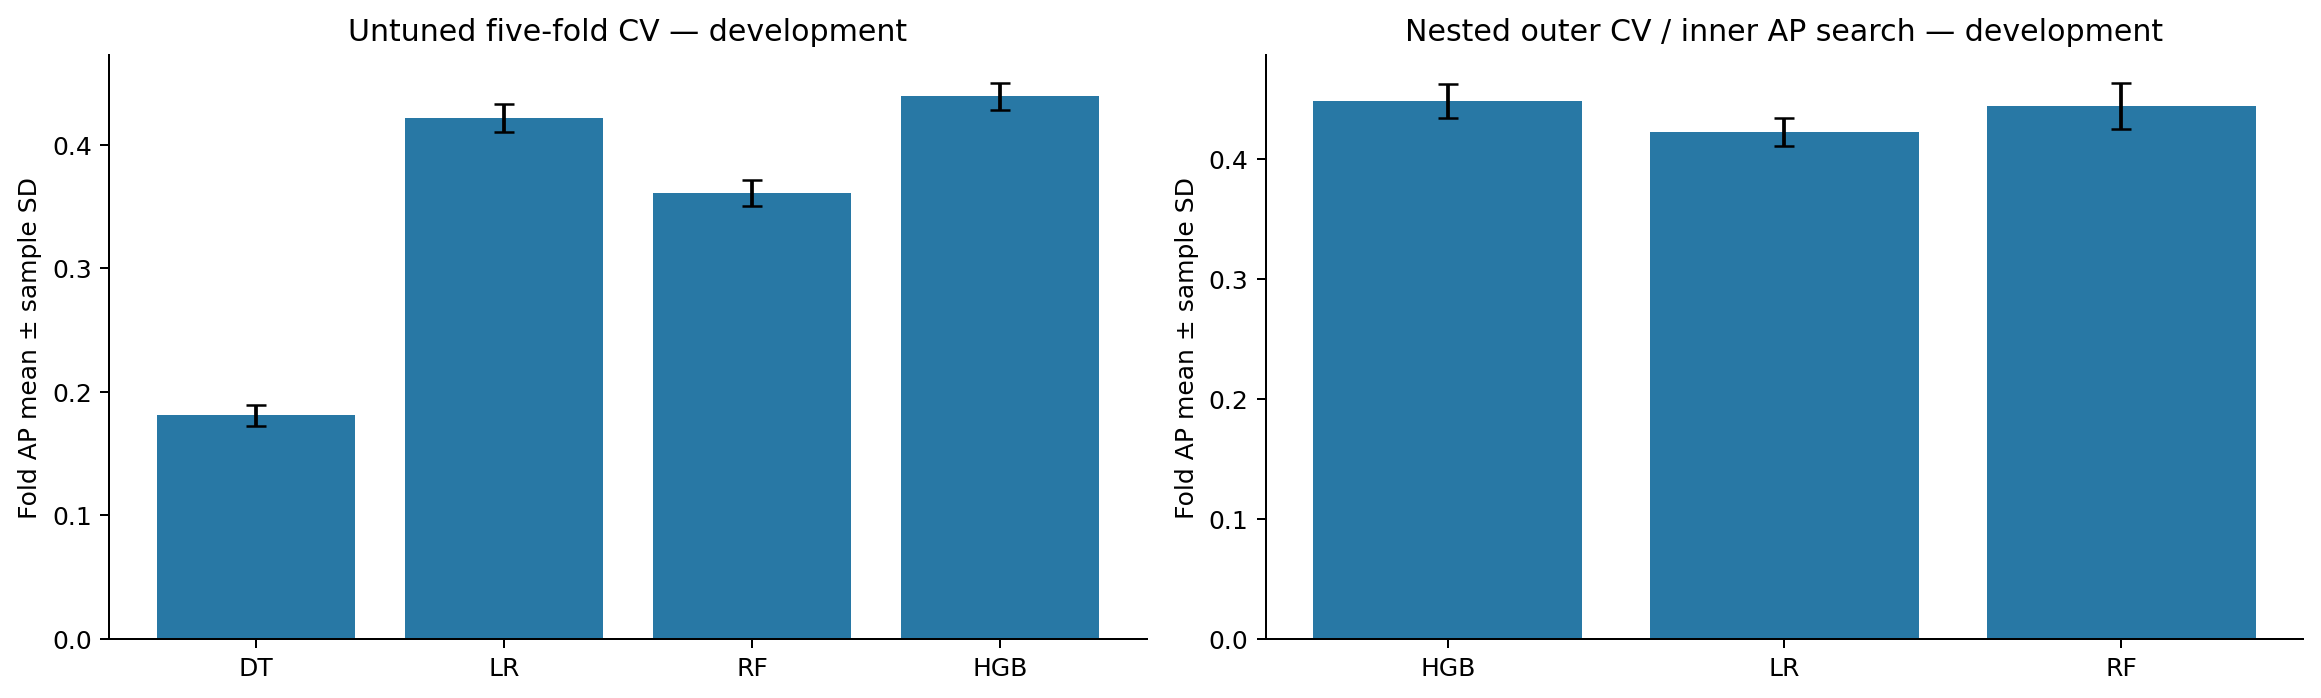

**03_model_comparison.png:** Untuned CV and nested CV are separate designs; no nested DT estimate exists; sample SD is not a significance test.  
Context/source: Phases 4/4B and 5A approved summary means

Source: [figures/03_model_comparison.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/03_model_comparison.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

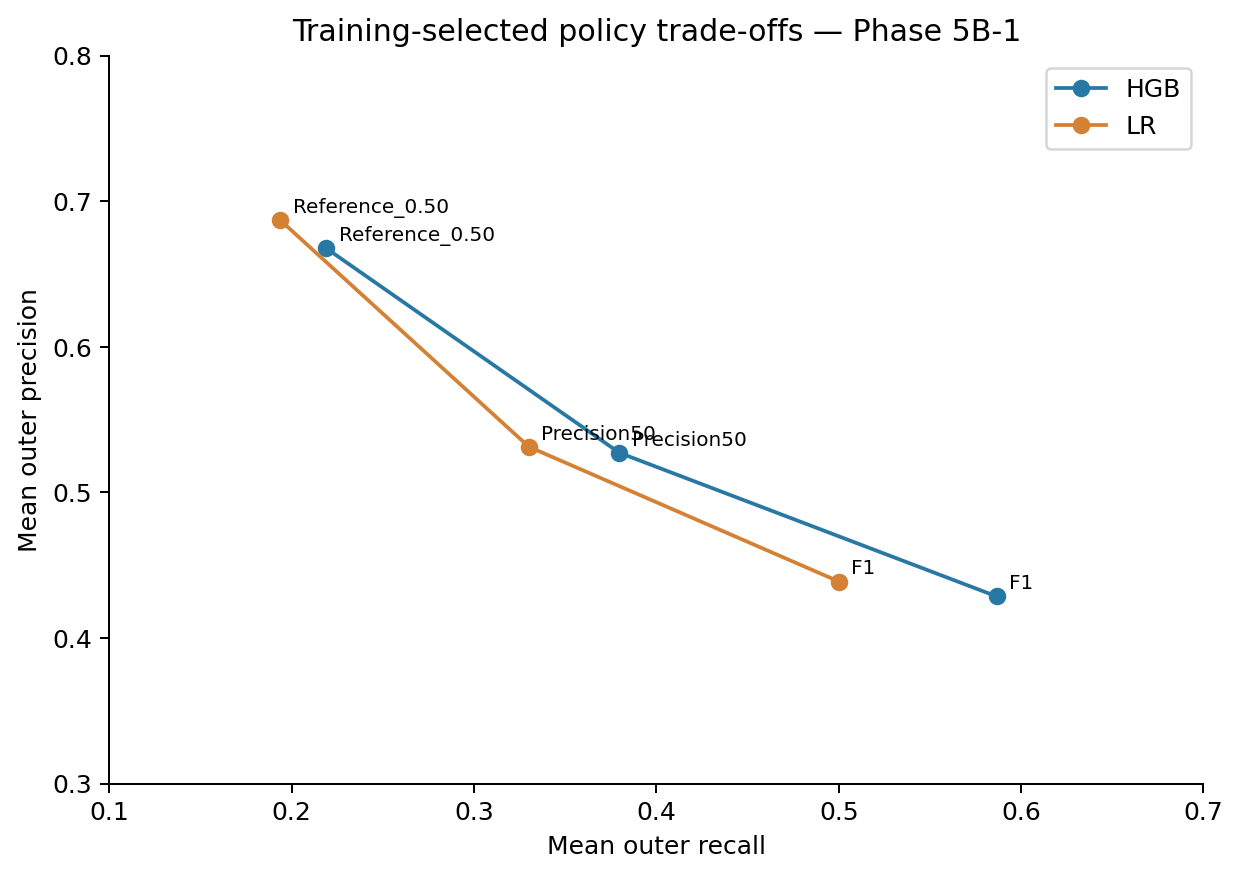

**04_threshold_tradeoff.png:** Frozen training-selected threshold policies evaluated on outer validation; connected points are policies, not an optimized test curve.  
Context/source: 07_threshold_decision_summary.md; development outer-fold means

Source: [figures/04_threshold_tradeoff.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/04_threshold_tradeoff.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

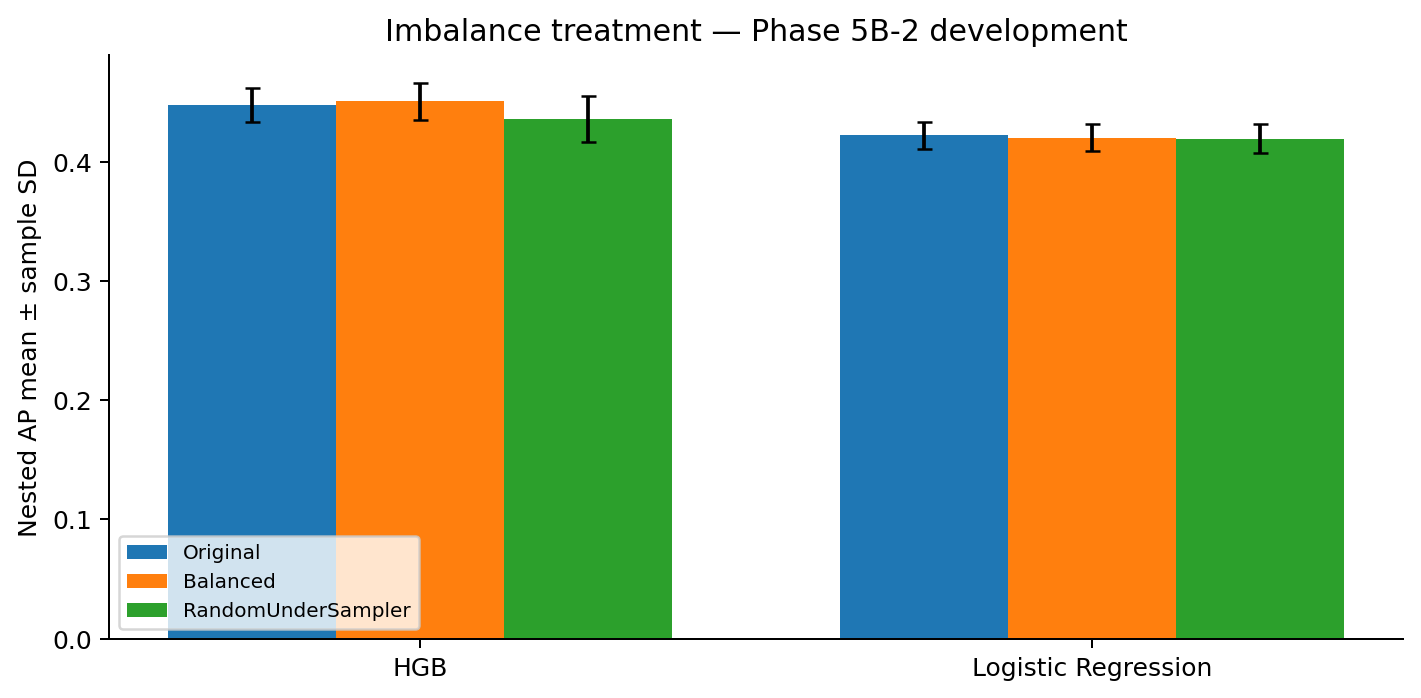

**05_imbalance_ap.png:** Symmetric-grid nested imbalance-treatment comparison; small balanced-HGB gain is not a significance conclusion.  
Context/source: 08_imbalance_treatment_summary.md

Source: [figures/05_imbalance_ap.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/05_imbalance_ap.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

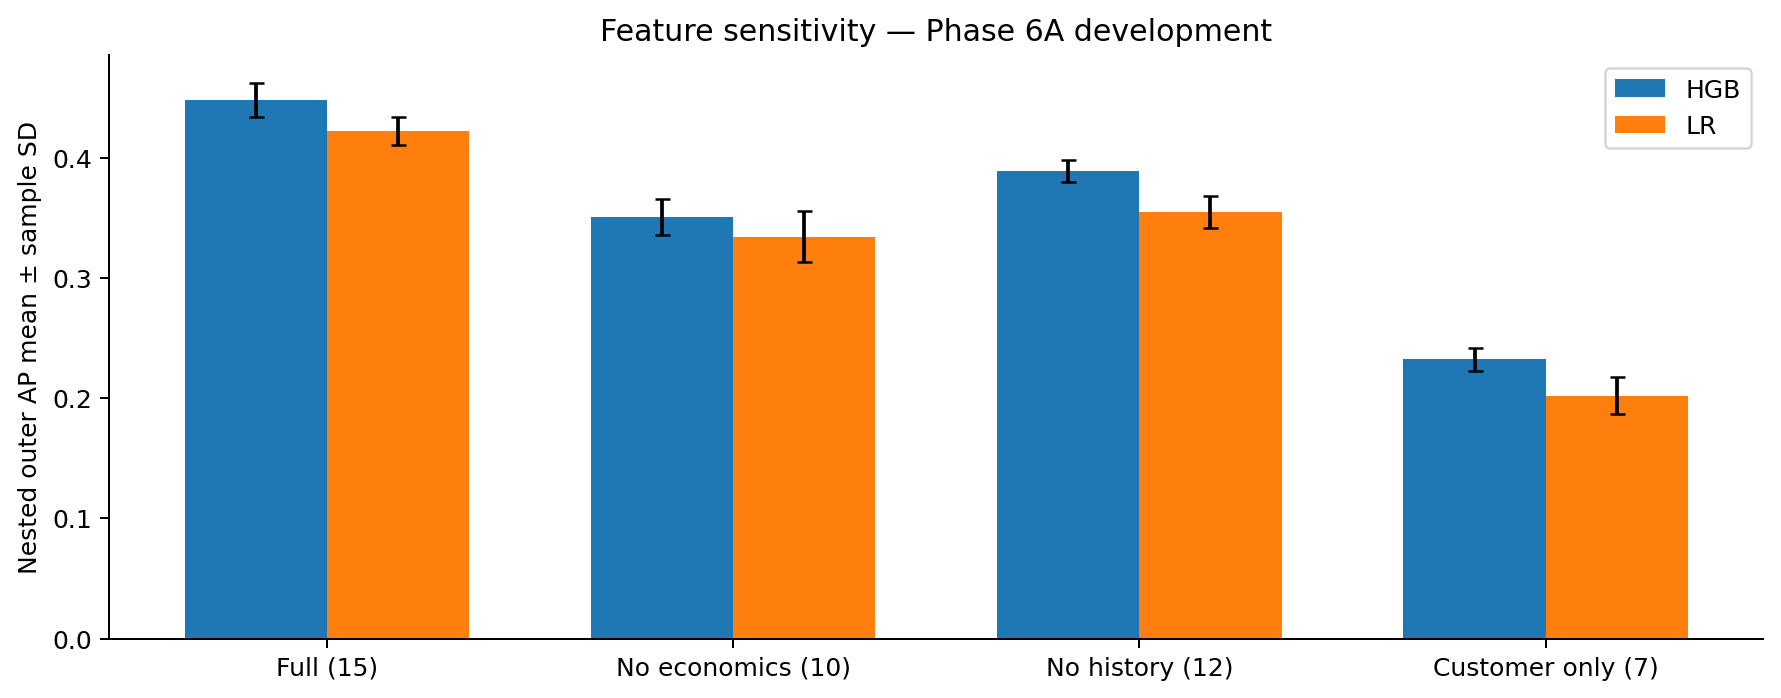

**06_feature_ablation.png:** Each prespecified subset independently tuned in nested CV; ablation does not certify feature availability.  
Context/source: 09_feature_ablation_summary.md

Source: [figures/06_feature_ablation.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/06_feature_ablation.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

In [6]:
assert REPLAY_OK
def aggregate_table(relative, header_fragment):
    text = ARCHIVE[relative].decode('utf-8')
    blocks = [b for b in text.split('\n\n') if b.startswith('|') and header_fragment in b.splitlines()[0]]
    if len(blocks) != 1:
        raise ValueError(f'FAIL: expected one approved aggregate table in {relative}: {header_fragment}')
    return blocks[0]
research = [
 ('06_nested_cv_targeting_summary.md','| model | Accuracy mean', 'Nested outer-CV model comparison'),
 ('07_threshold_decision_summary.md','| model | policy | Accuracy mean','Outer-validation threshold policies'),
 ('08_imbalance_treatment_summary.md','| Model | Original | Balanced','Nested imbalance-treatment AP'),
 ('09_feature_ablation_summary.md','| model | feature_group | AP mean','Nested feature-ablation metrics')]
for relative, header, title in research:
    display(Markdown('### Development / Nested CV — '+title))
    display(Markdown(aggregate_table(relative,header)))
    source(relative)
# Use approved static research charts so experimental contexts stay explicit.
for filename in ['03_model_comparison.png','04_threshold_tradeoff.png','05_imbalance_ap.png','06_feature_ablation.png']:
    archived_figure(filename)


## E — Frozen-model explanations (Development only, in-sample)
These are approved static Phase 8 images. No SHAP or permutation calculation runs here. Development observations were already used to train the frozen models, so the explanations describe model behavior rather than independent feature contribution. Correlated economic variables share information. Group permutation is joint sensitivity; individual drops are not additive. SHAP explains positive-class raw log-odds, and grouped categorical attributions use signed within-field sums, not a new original-feature Shapley game.

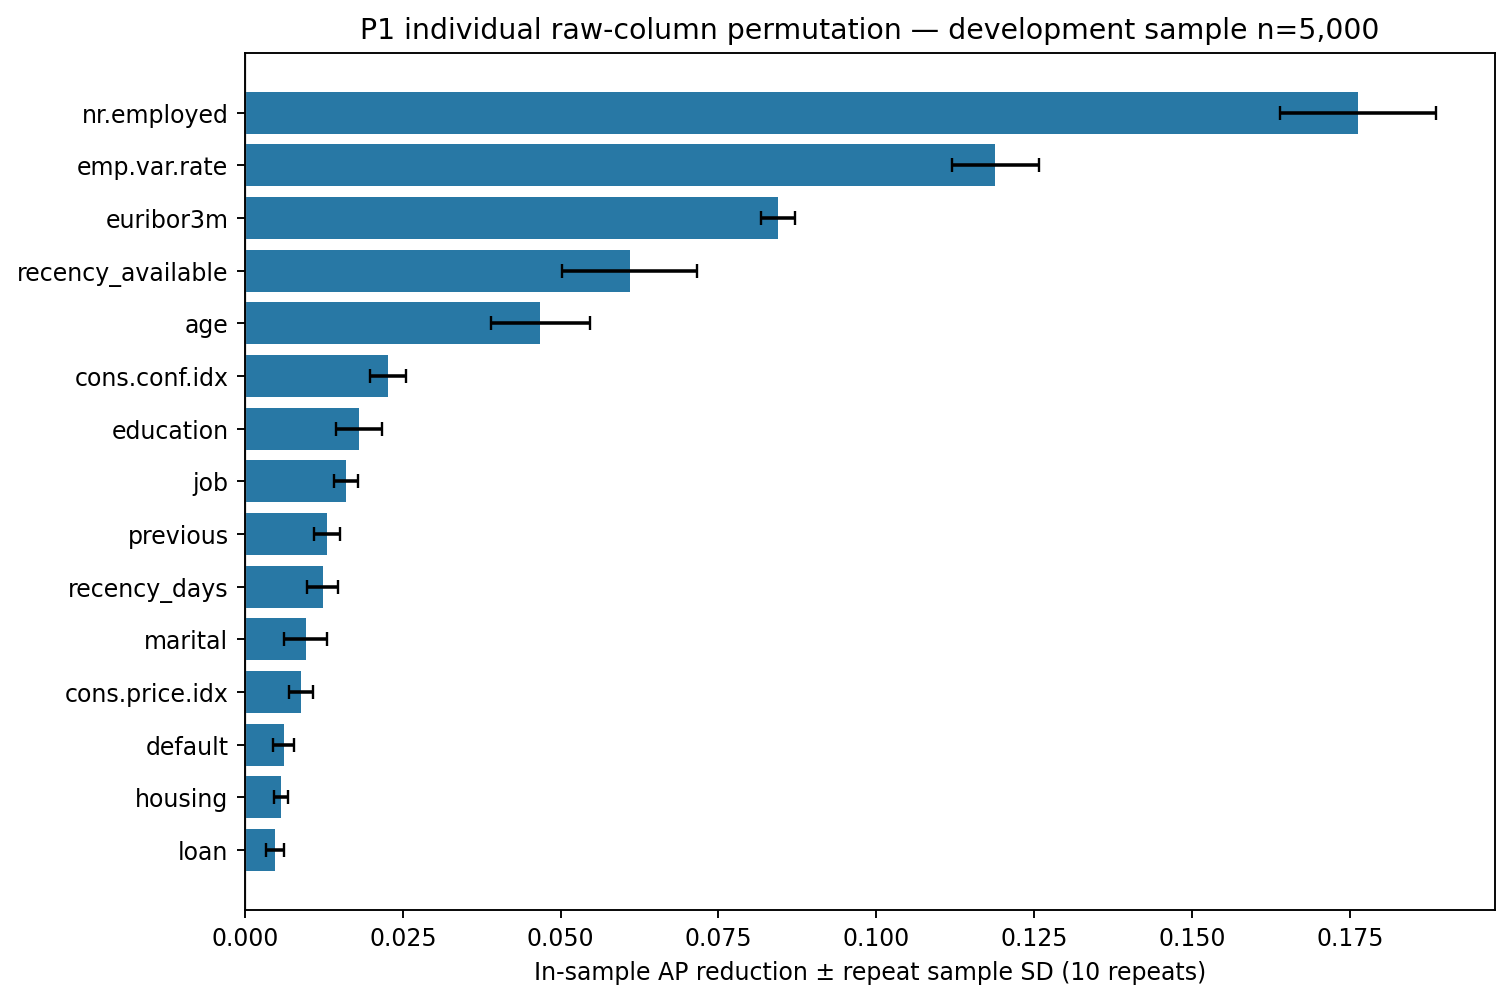

**09_permutation_individual.png:** P1 individual raw-column permutation; development-only in-sample, ten repeats; SD is permutation dispersion, not a generalization CI.  
Context/source: Phase 8; frozen P1, no refitting

Source: [figures/09_permutation_individual.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/09_permutation_individual.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

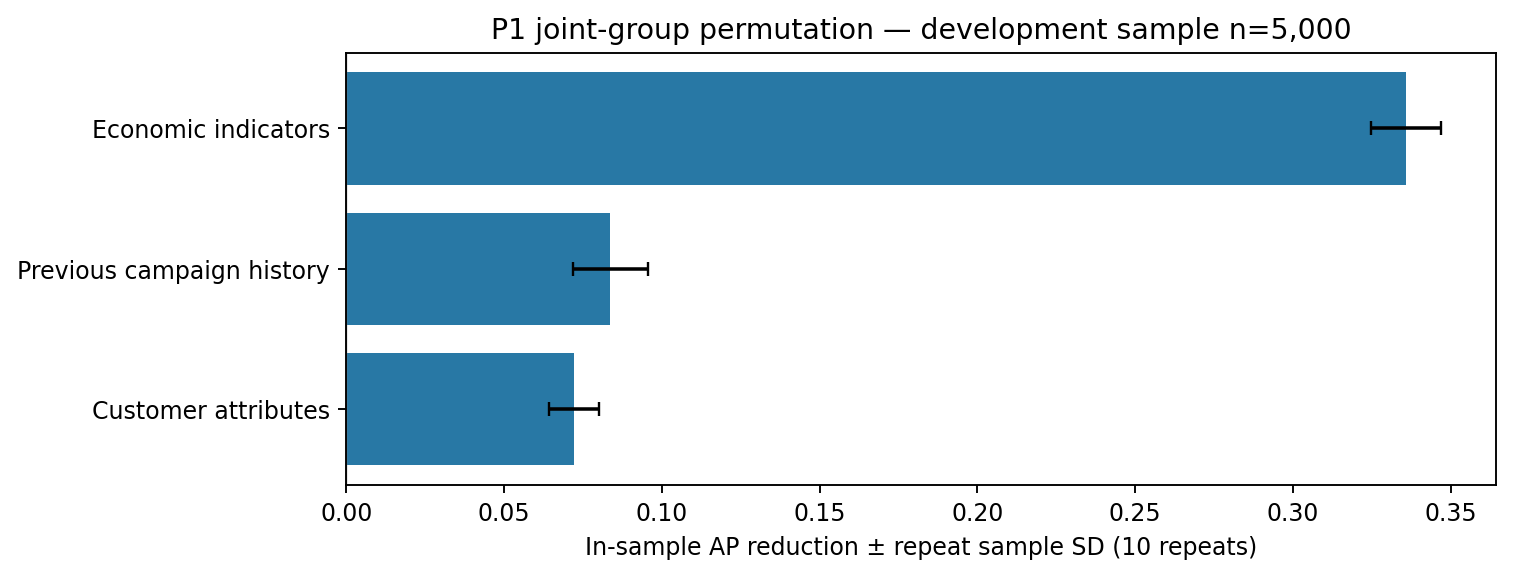

**10_permutation_groups.png:** P1 joint-group permutation; development-only in-sample, ten repeats; SD is permutation dispersion, not a generalization CI.  
Context/source: Phase 8; frozen P1, no refitting

Source: [figures/10_permutation_groups.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/10_permutation_groups.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

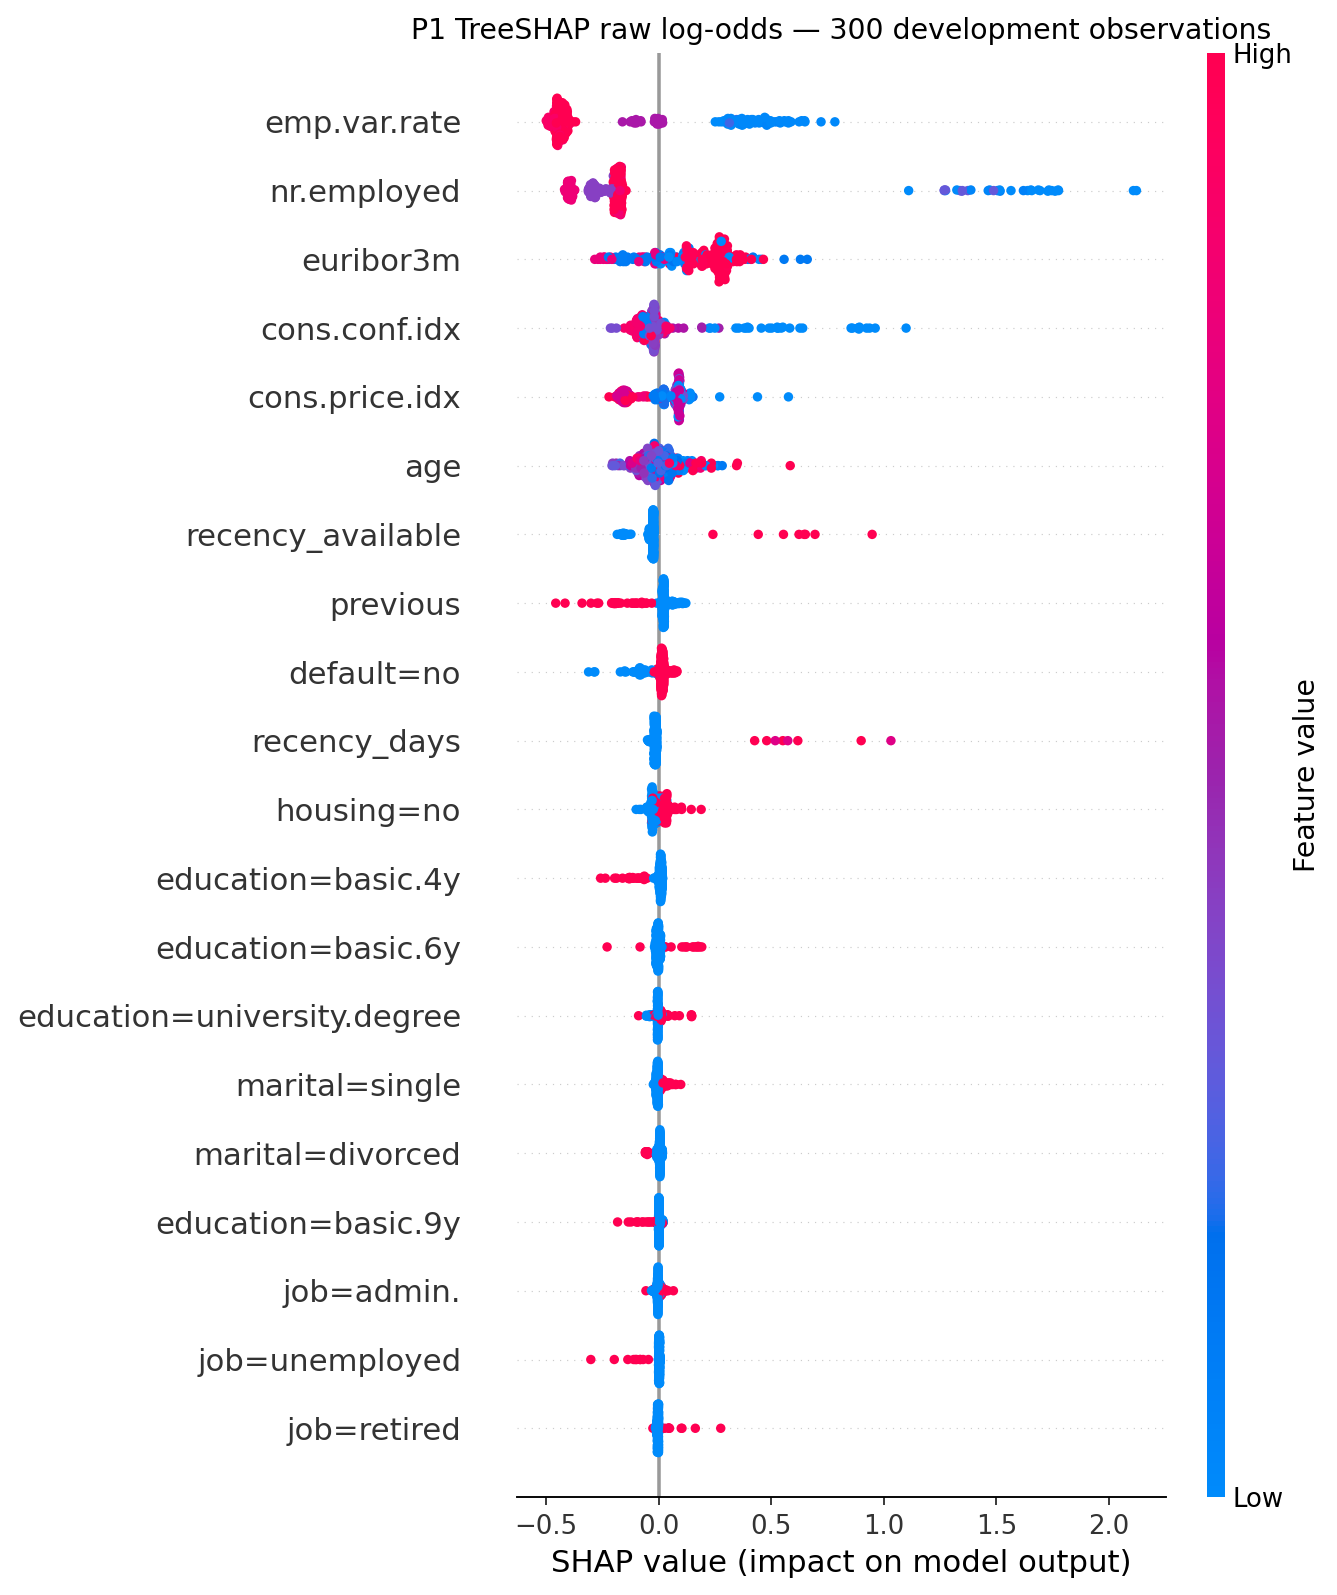

**11_shap_beeswarm.png:** TreeSHAP encoded-feature beeswarm; raw log-odds for class 1; color is transformed feature value.  
Context/source: Phase 8; tree-path-dependent reference; development in-sample

Source: [figures/11_shap_beeswarm.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/11_shap_beeswarm.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

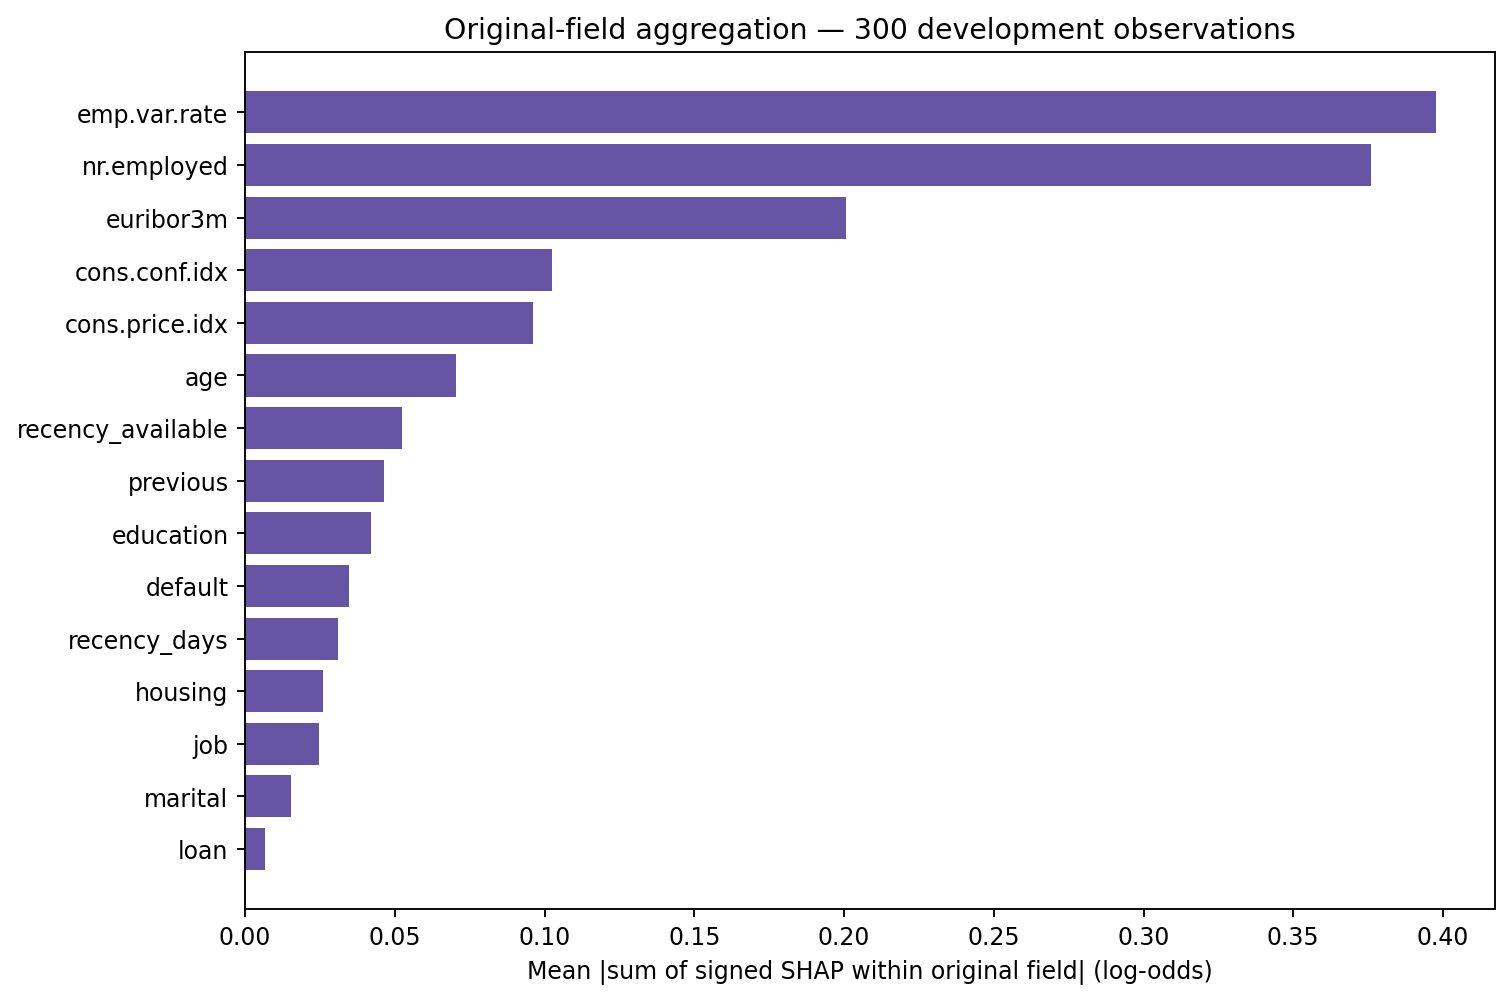

**12_shap_grouped_bar.png:** Mean absolute signed-within-field SHAP sums; encoded-game aggregation, not a recomputed original-variable Shapley game.  
Context/source: Phase 8; development in-sample

Source: [figures/12_shap_grouped_bar.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/12_shap_grouped_bar.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

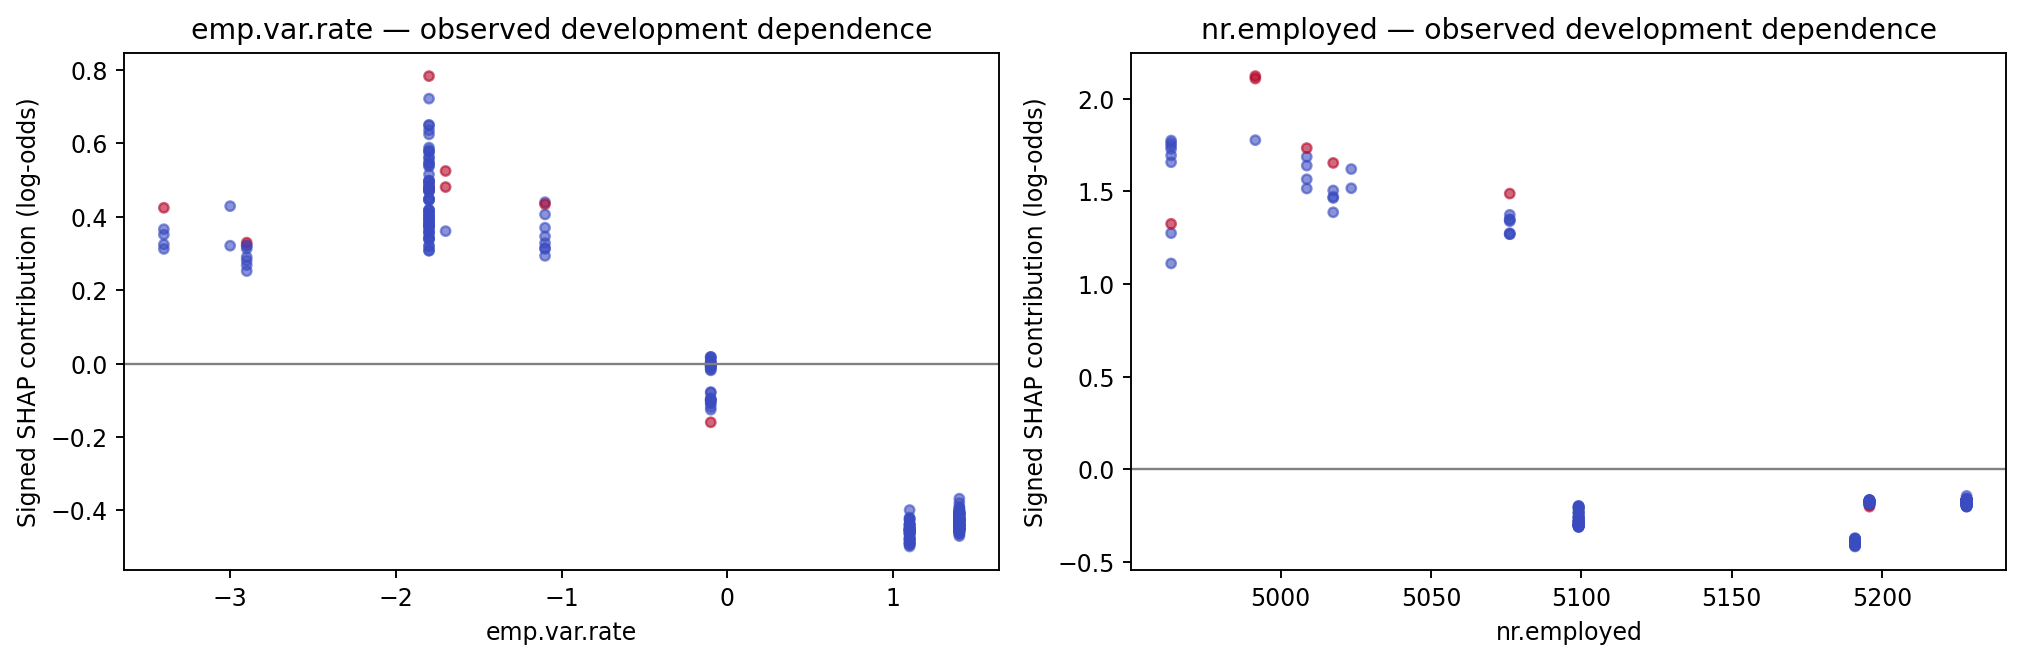

**13_shap_dependence.png:** Observed numerical value versus signed original-field contribution; color indicates recency availability; associations, not intervention responses.  
Context/source: Phase 8; 300 development observations

Source: [figures/13_shap_dependence.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/13_shap_dependence.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

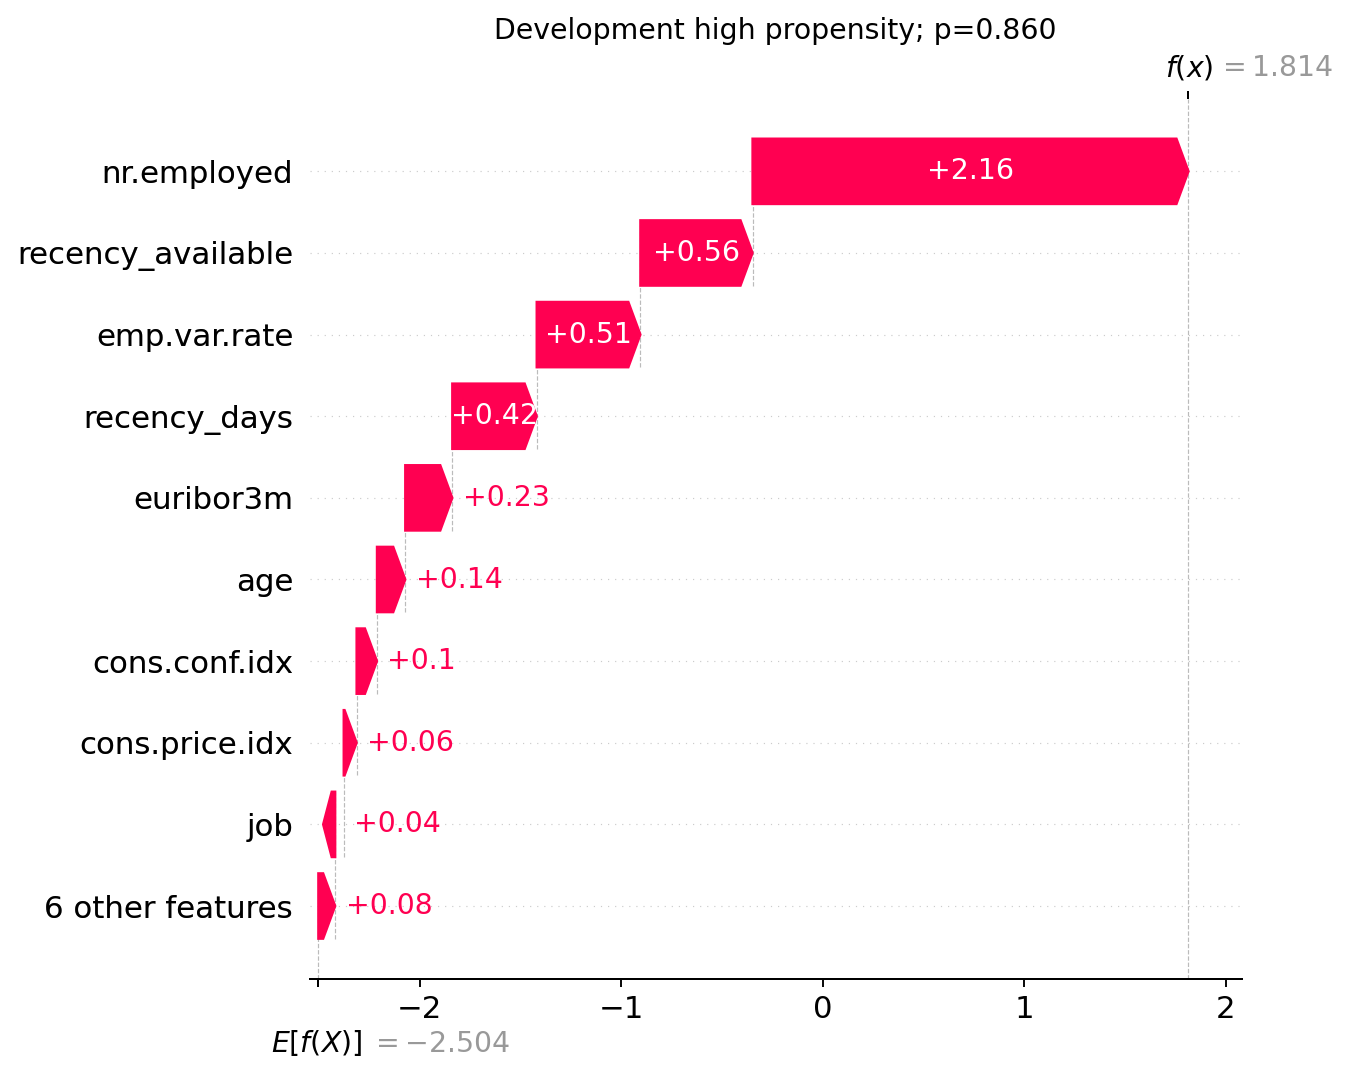

**14_shap_local_high.png:** Local high predicted-propensity example chosen by predeclared score rank, not observed outcome; grouped signed log-odds contributions.  
Context/source: Phase 8; development only; no causal intervention

Source: [figures/14_shap_local_high.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/14_shap_local_high.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

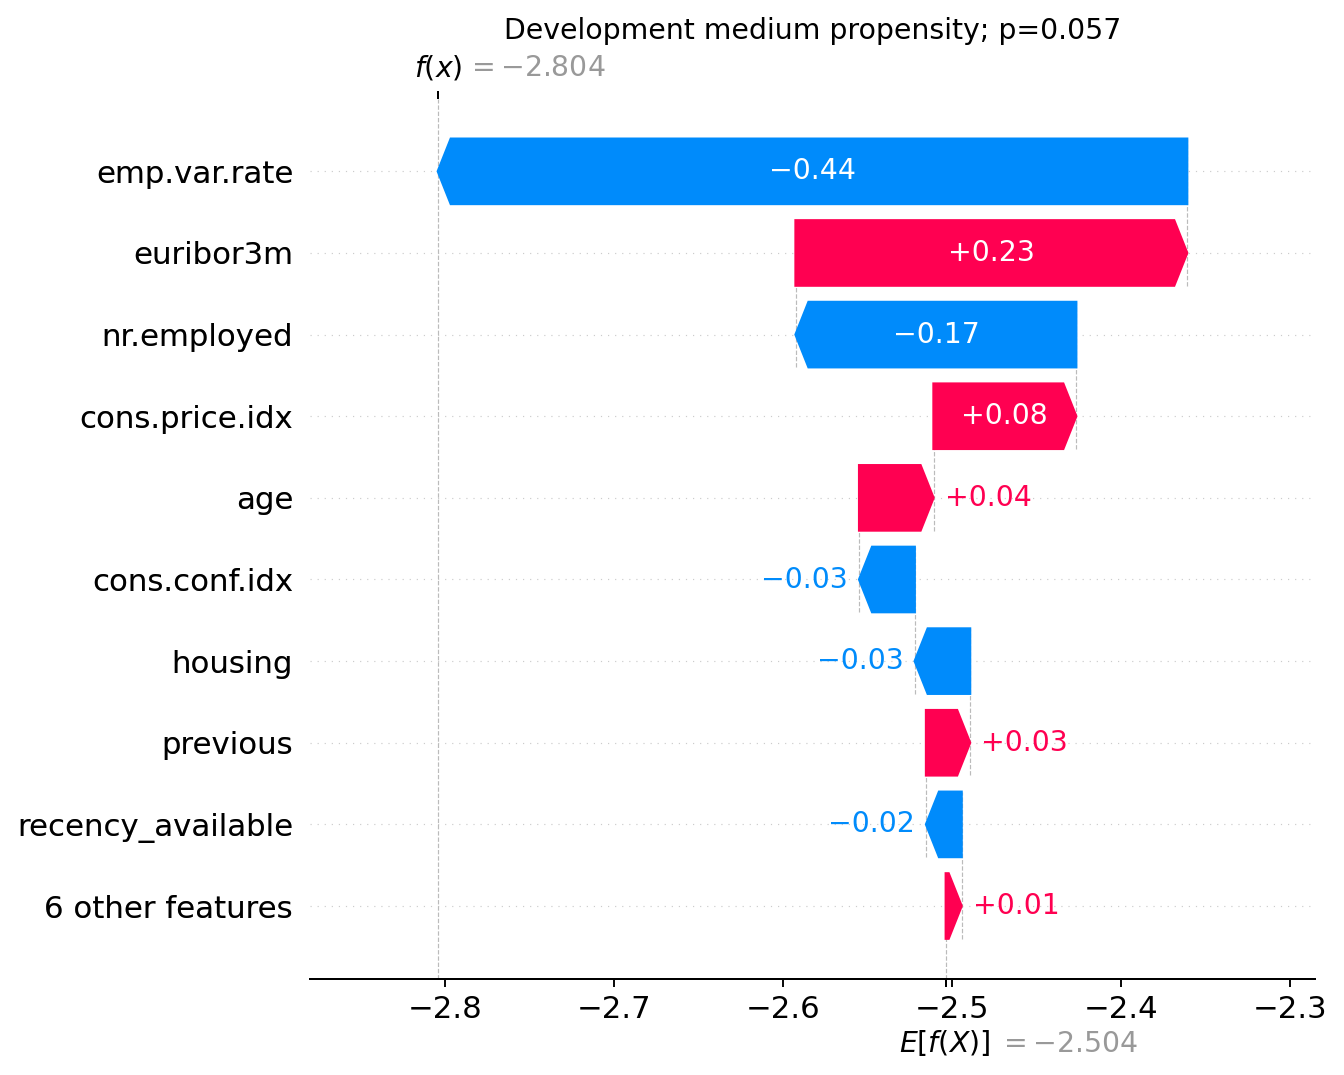

**15_shap_local_medium.png:** Local medium predicted-propensity example chosen by predeclared score rank, not observed outcome; grouped signed log-odds contributions.  
Context/source: Phase 8; development only; no causal intervention

Source: [figures/15_shap_local_medium.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/15_shap_local_medium.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

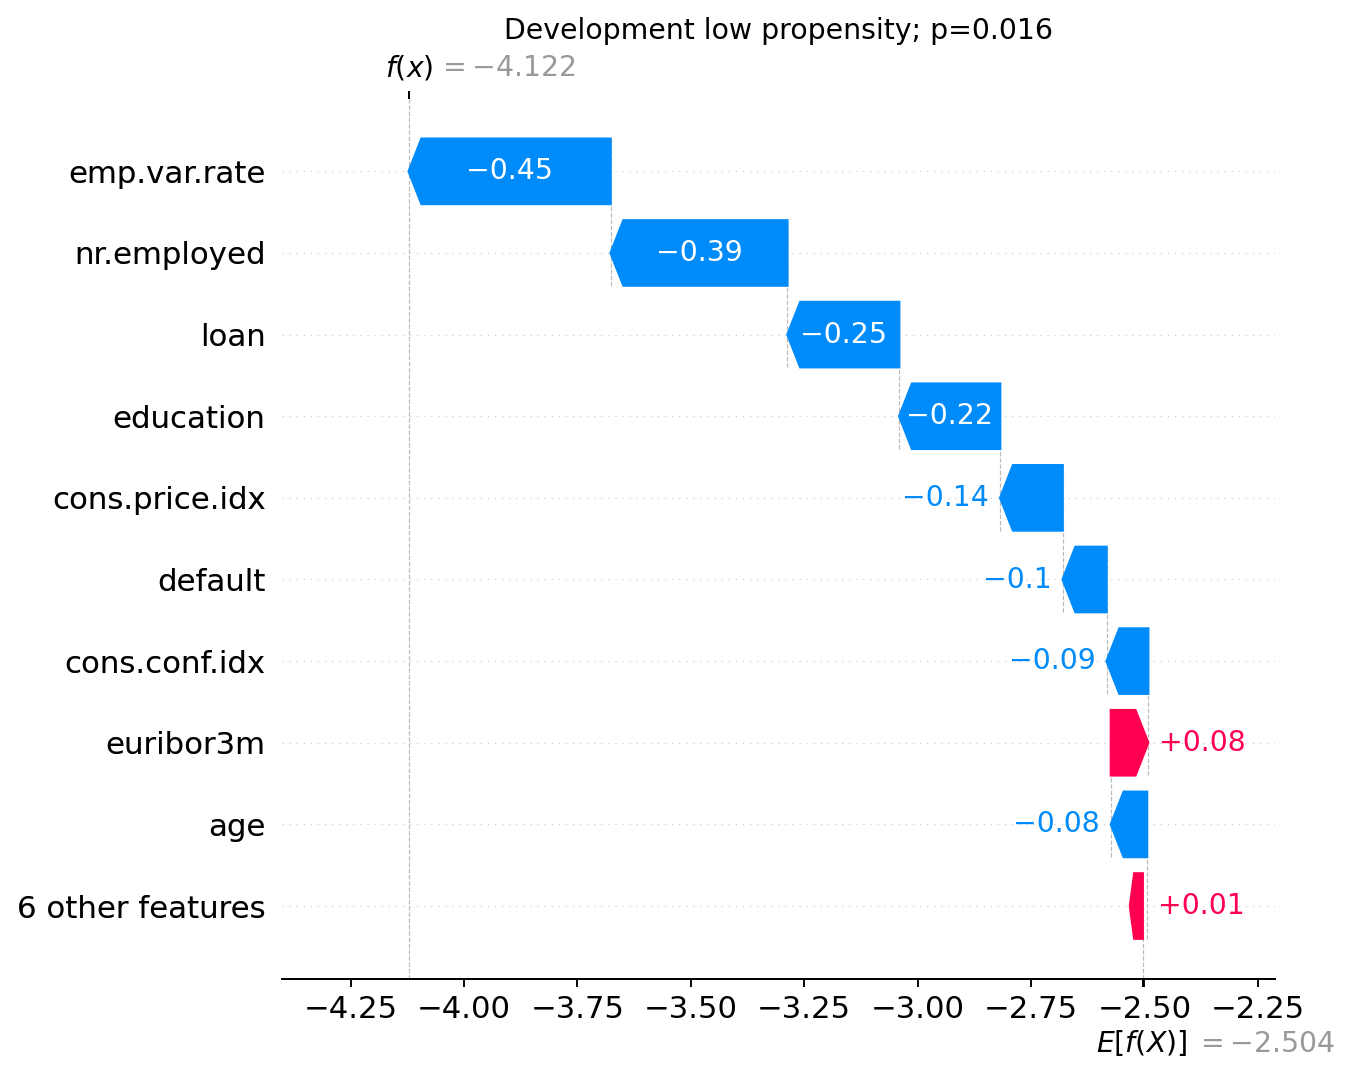

**16_shap_local_low.png:** Local low predicted-propensity example chosen by predeclared score rank, not observed outcome; grouped signed log-odds contributions.  
Context/source: Phase 8; development only; no causal intervention

Source: [figures/16_shap_local_low.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/16_shap_local_low.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

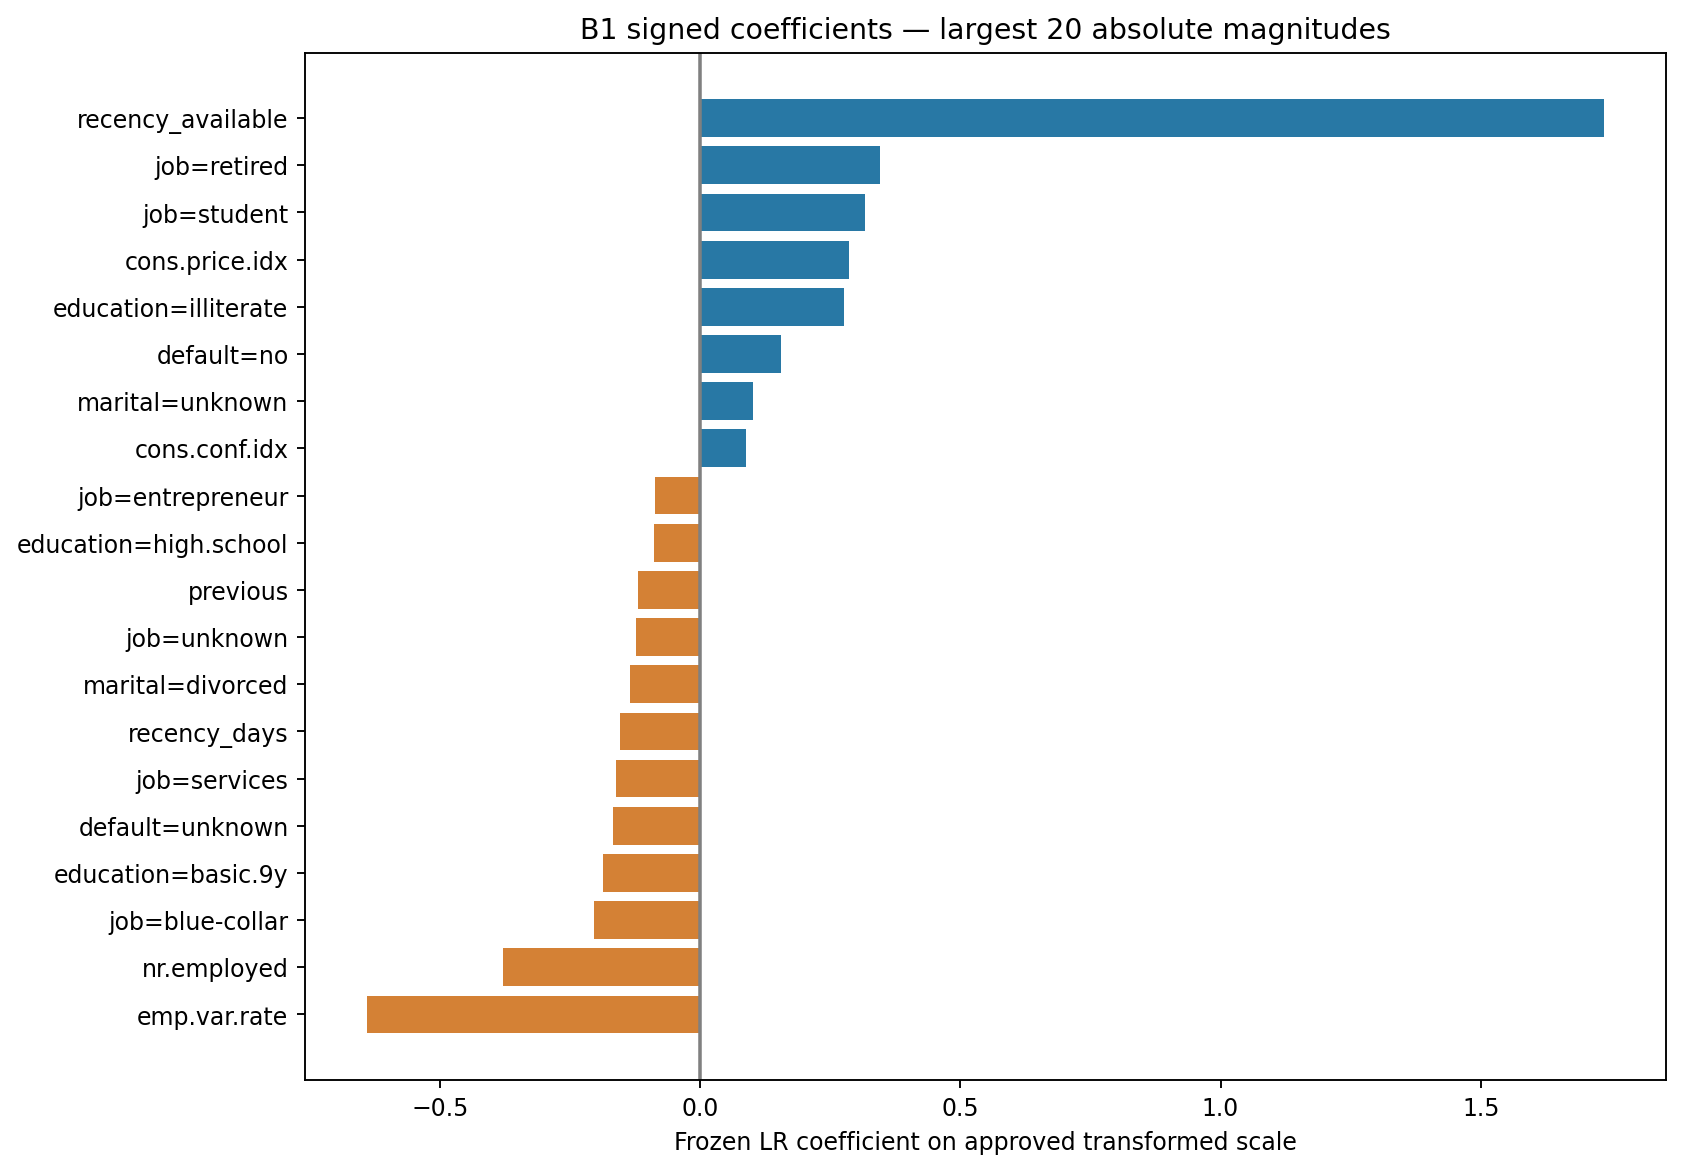

**17_lr_coefficients.png:** B1 coefficients on standardized numerical/full-one-hot scale; not causal effects or unadjusted original-unit importance.  
Context/source: Phase 8; frozen B1, alignment checked with development logits

Source: [figures/17_lr_coefficients.png](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/17_lr_coefficients.png); [figures/figure_inventory.md](https://github.com/amyfish1999/bank-marketing-ml/blob/d41bd3450b17370c8f364c895f3771e5b0a093f4/figures/figure_inventory.md)

In [7]:
assert REPLAY_OK
for filename in ['09_permutation_individual.png','10_permutation_groups.png','11_shap_beeswarm.png','12_shap_grouped_bar.png','13_shap_dependence.png','14_shap_local_high.png','15_shap_local_medium.png','16_shap_local_low.png','17_lr_coefficients.png']:
    archived_figure(filename)

## F — What the results mean
HGB was shortlisted because of its Development nested-CV ranking and targeting results; P1's primary role was fixed before testing. The archived test results provide one historical assessment, not a new selection opportunity. Fixed-capacity targeting ranks customers within a predefined outreach budget rather than requiring a probability threshold of 0.50.

Economic indicators and history carry substantial predictive information, consistent with the feature-ablation findings. Their importance also highlights unresolved publication, snapshot and reference-date timing. All 15 predictors remain Provisional. Missing customer IDs and campaign timestamps prevent confirmation of customer-independent or future-period generalization. Neither predictive lift nor SHAP establishes causal marketing uplift. No ROI is estimated.

**Replay complete:** only archived aggregate tables, documentation and approved images were read. Original artifacts are never written. For the complete interpretation see `14_final_academic_report.md`; for provenance see the source links beneath each output.

## Replay validation record
All seven code cells passed a local Colab-style path simulation using only approved archive inputs. Tables and 16 inline images rendered. Missing-source and changed-digest tests stopped correctly. No model/dataset/row-prediction files were opened by replay; no archive files were written. All previous project files remained unchanged. This was not a live hosted Colab test.